# Introducrtion to Machine Learning: Assignment #5
## Submission date: 31\07\2026, 23:59.
### Topics:
- AdaBoost
- Clustering
- PCA, LDA
- Deep Learning

Submitted by:

 Rawa Abu salah  ID:325143634

 Reema khalaily  ID:214281479

**Assignment Instruction:**

· Submissions in pairs only.

· Try to keep the code as clean, concise, and short as possible

· If you wish to work in your IDE, you can, but you **must**,  insert the script back to the matching cells of the notebook and run the code. <br/>Only the notebook will be submitted in moodle (in `.ipynb` format).

· <font color='red'>Please write your answers to question in red</font>.

**Important:** All plots, results and outputs should be included in the notebook as the cells' outputs (run all cells and do not clear the output). <br/>

**Important:** Your submission must be entirely your own. Any attempts of plagiarism (including ChatGPT) will lead to grade 0 and disciplinary actions.


## Question 1 - Clustering

We learned in the tutorials about partitional clustering.<br/>
In this question you will implement Kmeans, see new algorithms and analyze students behaviour from dataset.

import libraries

In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

Complete the missing implementation of Kmeans. Since there are k clusters, we will label each point with {0,..,k-1}.

In [61]:
class Kmeans:

    def __init__(self, n_clusters, max_iter=1000, random_state=54):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.random_state = random_state

    def initialize_centroids(self, X):
        random_idx = np.random.permutation(X.shape[0])
        centroids = X[random_idx[:self.n_clusters]]
        return centroids

    def reassign_centroids(self, X, labels):
        centroids = np.zeros((self.n_clusters, X.shape[1]))

        for k in range(self.n_clusters):
            cluster_points = X[labels == k]

            if cluster_points.shape[0] > 0:
                centroids[k] = np.mean(cluster_points, axis=0)
            else:
                random_index = np.random.randint(X.shape[0])
                centroids[k] = X[random_index]

        return centroids

    def compute_distance(self, X, centroids):
        distance = np.zeros((X.shape[0], self.n_clusters))

        for k in range(self.n_clusters):
            row_norm = np.linalg.norm(X - centroids[k, :], axis=1)
            distance[:, k] = np.square(row_norm)

        return distance

    def find_closest_cluster(self, distance):
        return np.argmin(distance, axis=1)

    def compute_sse(self, X, labels, centroids):
        distance = np.zeros(X.shape[0])

        for k in range(self.n_clusters):
            distance[labels == k] = np.linalg.norm(X[labels == k] - centroids[k],axis=1)

        return np.sum(np.square(distance))

    def fit(self, X):
        np.random.seed(self.random_state)

        self.centroids = self.initialize_centroids(X)

        for i in range(self.max_iter):
            old_centroids = self.centroids.copy()

            distance = self.compute_distance(X, self.centroids)

            self.labels = self.find_closest_cluster(distance)

            self.centroids = self.reassign_centroids(X, self.labels)

            if np.allclose(old_centroids, self.centroids):
                break

        self.error = self.compute_sse(X,self.labels,self.centroids)

    def predict(self, X):
        distance = self.compute_distance(X, self.centroids)
        return self.find_closest_cluster(distance)

Load the student_droupoout data.
| Column Name | Type | Description |
|------------|------|-------------|
| `student_id` | `int64` | Unique student identifier |
| `name` | `object` | Student name (should be anonymized before use) |
| `age` | `int64` | Age of the student (years) |
| `gender` | `object` | Gender of the student |
| `quiz1_marks` | `float64` | Marks obtained in Quiz 1 (0-10) |
| `quiz2_marks` | `float64` | Marks obtained in Quiz 2 (0-10) |
| `quiz3_marks` | `float64` | Marks obtained in Quiz 3 (0-10) |
| `total_assignments` | `int64` | Total number of assignments assigned |
| `assignments_submitted` | `float64` | Number of assignments submitted (`NaN` in current dataset) |
| `midterm_marks` | `float64` | Marks obtained in midterm exam (0-30) |
| `final_marks` | `float64` | Marks obtained in final exam (0-50) |
| `previous_gpa` | `float64` | GPA from previous semester (0-4 scale) |
| `lectures_attended` | `float64` | Precentage of lectures attended |
| `labs_attended` | `float64` | Precentage of lab sessions attended |

In [62]:
df = pd.read_csv('https://sharon.srworkspace.com/ml/datasets/hw4/student_dropout.csv')
df.head(4)

,student_id,name,age,gender,quiz1_marks,quiz2_marks,quiz3_marks,total_assignments,assignments_submitted,midterm_marks,final_marks,previous_gpa,lectures_attended,labs_attended
0,1,Kristina Vaughan,19,Male,8.0,5.7,7.4,5,NaN,30.0,36.5,2.57,0.33,0.17
1,2,Rodney Daniels,21,Male,10.0,7.9,4.1,5,NaN,25.4,33.0,2.40,0.08,0.83
2,3,Jose Nash,19,Female,7.5,1.2,0.3,5,NaN,14.4,24.8,2.99,0.00,0.00
3,4,Nicole Martin,21,Male,5.2,2.5,9.9,5,NaN,17.7,41.0,1.68,0.75,0.00


Tasks:
1. drop 4 features which has absolutely zero contribution.
2. Covert any discrete feature left into float.
3. Convert the three quizzes to one feature - their average.


In [63]:
df = df.drop(columns=['student_id', 'name', 'total_assignments', 'assignments_submitted'])

df['gender'] = df['gender'].map({'Male': 0, 'Female': 1})

df['quiz_average'] = df[['quiz1_marks', 'quiz2_marks', 'quiz3_marks']].mean(axis=1)

df = df.drop(columns=['quiz1_marks', 'quiz2_marks', 'quiz3_marks'])

df = df.astype(float)

df.head()

,age,gender,midterm_marks,final_marks,previous_gpa,lectures_attended,labs_attended,quiz_average
0,19.0,0.0,30.0,36.5,2.57,0.33,0.17,7.033333
1,21.0,0.0,25.4,33.0,2.40,0.08,0.83,7.333333
2,19.0,1.0,14.4,24.8,2.99,0.00,0.00,3.000000
3,21.0,0.0,17.7,41.0,1.68,0.75,0.00,5.866667
4,21.0,1.0,23.8,31.0,2.53,0.58,0.67,4.733333


Answer the following questions:
1. Can the previous semester GPA imply anything about the final marks?
<font color='red'> no ,the previous semester GPA dosen't indicate anything about the final marks , as we can see there is no clear correlation between the two features </font>

2. Can the gender can imply anything about the final marks?

<font color='red'> no , we can't include from the given data that gender affects the final marks, there is no correlation between the two features </font>

3. Can lectures_attended / labs_attended imply anything about the final marks?
<font color='red'> no we can not infer from the results that there is clear correlation between labs and lectures attendance and final grades, because we got numbers that very close to zero which means there is no correlation</font>
<font color='red'>Write here your answers and explain.</font>

In [64]:
print("Correlation between previous_gpa and final_marks:")
print(df['previous_gpa'].corr(df['final_marks']))

print("\nAverage final marks by gender:")
print(df.groupby('gender')['final_marks'].mean())

print("\nCorrelation between lectures_attended and final_marks:")
print(df['lectures_attended'].corr(df['final_marks']))

print("\nCorrelation between labs_attended and final_marks:")
print(df['labs_attended'].corr(df['final_marks']))

Correlation between previous_gpa and final_marks:
0.1010892038637543

Average final marks by gender:
gender
0.0    36.053103
1.0    38.611613
Name: final_marks, dtype: float64

Correlation between lectures_attended and final_marks:
-0.019351153264256973

Correlation between labs_attended and final_marks:
0.10737256432181304


Here comes the interesting part. <br/>
Unlike in the tutorial, you cannot just "plot" a 2d/3d map of features and nice shperes and conclude anything. Hence, you will do the following:

Task 1: In the following cell, define a kmeans object with 2 clusters. fit to the data and print the features as name: value of both centroids.

- Do not forget to use MinMaxScaler
- When printing the feature, use 'inverse_transform'.

<!--Oh my bad - please use StandardScaler -->

In [65]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X = scaler.fit_transform(df)

kmeans = Kmeans(n_clusters=2)
kmeans.fit(X)

centroids = scaler.inverse_transform(kmeans.centroids)

centroids_df = pd.DataFrame(centroids, columns=df.columns)

print(centroids_df)

         age  gender  midterm_marks  final_marks  previous_gpa  \
0  21.529032     1.0      20.093548    38.611613      2.881871   
1  21.572414     0.0      19.835862    36.053103      2.724966   

   lectures_attended  labs_attended  quiz_average  
0           0.516581       0.521355      6.194624  
1           0.484207       0.515310      6.199080  


Task 2: Use elbow method to find the "best" nubmer of centroids between 1-10.<br/>

<font color='red'> according to the elbow method i would choose K=5 because for k smaller than 5 the model is too simple and may underfit the data, after K = 5, adding more clusters reduces the SSE slightly and the model complexity will increase , which may lead to overfitting.</font>

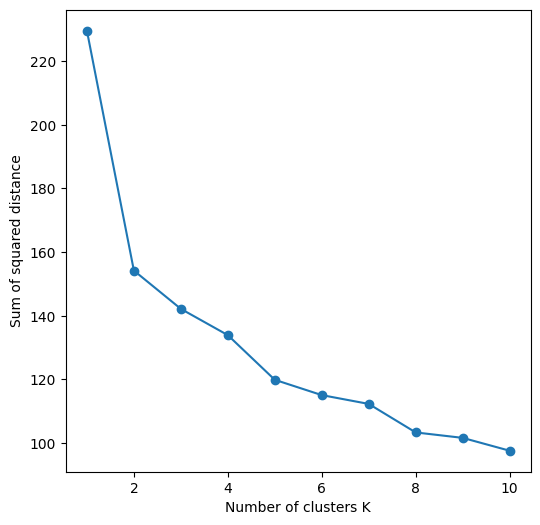

In [66]:
sse = []
list_k = list(range(1, 11))

for k in list_k:
    kmeans = Kmeans(n_clusters=k)
    kmeans.fit(X)
    sse.append(kmeans.error)

plt.figure(figsize=(6,6))
plt.plot(list_k, sse, '-o')
plt.xlabel("Number of clusters K")
plt.ylabel("Sum of squared distance")
plt.show()

Task 3: Repeat task 1 but with 3 centroids and using the real KMeans object (they implemented it better, what can I say?)

1. Explain the clusters found, in terms of analyzing the students belong to each cluster.

<font color='red'> culster 1 describes students with the highest lab and lecture rate and we notice that they got the highest grades</font>

<font color='red'>
cluster 2 describes students who got moderate lab and lecture attendance and avarage grades. </font>
<font color='red'>
cluster 3 decribes the lowest lecture and lab attendance with the lowest grades.
</font>

2. What features did not contribute? In other words, ~same for all clusters. Based on that answer, suggest to Sharon how to change the grade components for the next semester.

<font color='red'> the features age, midterm marks, and quiz average are very similar foa all the three clusters, so the affected the process of clustring slightly, so i suggest for sharon to reduce thier weight </font>

In [67]:
from sklearn.cluster import KMeans

kmeans_real = KMeans(n_clusters=3, random_state=54, n_init=10)
kmeans_real.fit(X)

centroids = scaler.inverse_transform(kmeans_real.cluster_centers_)

centroids_df = pd.DataFrame(centroids, columns=df.columns)
centroids_df.index = ['Cluster 1', 'Cluster 2', 'Cluster 3']

print(centroids_df)

                 age        gender  midterm_marks  final_marks  previous_gpa  \
Cluster 1  21.542169  1.000000e+00      20.138554    38.679518      2.832892   
Cluster 2  21.572414  6.661338e-16      19.835862    36.053103      2.724966   
Cluster 3  21.513889  1.000000e+00      20.041667    38.533333      2.938333   

           lectures_attended  labs_attended  quiz_average  
Cluster 1           0.610482       0.784819      6.223695  
Cluster 2           0.484207       0.515310      6.199080  
Cluster 3           0.408333       0.217639      6.161111  


## load smiling dataset

From now on, we will deal with the Smiling-face dataset, which determines if a person is smiling or not.

You will try several models and hope to get good results<br/>
Your task is: run the following section and make sure your understand what's going on.

Go to your <a href="https://www.kaggle.com/">Kaggle</a> account and under the settings, generate new API token. <br/>
This will give you the json file, which you will upload here.

In [68]:
# The algorithm expects you to upload JSON file to it!

! pip install -q kaggle
from google.colab import files
files.upload()
! mkdir ~/.kaggle
! cp kaggle.json ~/.kaggle/
! chmod 600 ~/.kaggle/kaggle.json
! kaggle datasets list
! kaggle datasets download chazzer/smiling-or-not-face-data
! unzip -q smiling-or-not-face-data.zip -d data

Saving kaggle.json to kaggle (1).json
mkdir: cannot create directory ‘/root/.kaggle’: File exists
ref                                                             title                                                  size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------------------------  -----------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
harshadapatil31/student-performance-and-study-habits-dataset    Student Performance & Study Habits Dataset            15035  2026-07-06 06:28:52.743000           4522         68                1  
rishavsvault/most-streamed-artists-on-spotify                   Most Streamed Artists on Spotify                      37537  2026-07-24 16:55:05.213000           2191         43                1  
abbas829/ecommerce-sales-dataset                                Ecommerce sales dataset                           

import libraries

In [69]:
import numpy as np
from matplotlib import pyplot as plt
import os
import cv2

import warnings
warnings.filterwarnings('ignore')

process the images

In [70]:
def proccess_data(folder):
	image_arrays = []
	for filename in os.listdir(folder):
		file_path = os.path.join(folder, filename)
		image = cv2.imread(file_path)
		gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
		image_arrays.append(gray_image)
	return np.array(image_arrays)

smile = proccess_data('./data/smile')
non_smile = proccess_data('./data/non_smile')

dataset = np.vstack((non_smile, smile))
dataset = dataset / 255

labels = [0] * len(non_smile) + [1] * len(smile)
labels = np.array(labels)

display smiling and non-smiling image.

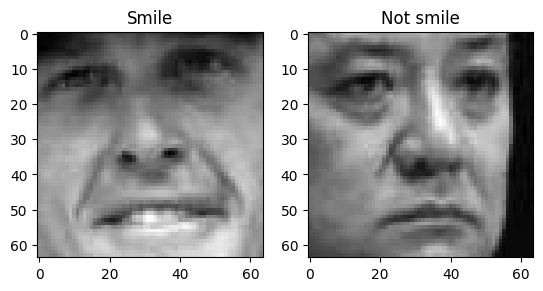

In [71]:
plt.subplot(121)
plt.title("Smile")
plt.imshow(smile[0], cmap='gray')

plt.subplot(122)
plt.title("Not smile")
plt.imshow(non_smile[0], cmap='gray')

plt.show()

print the smiling and non-smiling data + the united dataset along with labels.

In [72]:
print(f'smile array size is (images, height, width)={smile.shape}')
print(f'non smile array size is (images, height, width)={non_smile.shape}')
print()
print(f'dataset array size is {dataset.shape}')
print(f'labels array size is {labels.shape}')

smile array size is (images, height, width)=(600, 64, 64)
non smile array size is (images, height, width)=(603, 64, 64)

dataset array size is (1203, 64, 64)
labels array size is (1203,)


Prepear train and test datasets, print their structure. Since you have to deal with 1d features, we flatten the squared image

In [73]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(dataset, labels, test_size = 0.2, stratify=labels, random_state=42)

print(f'train size is {x_train.shape} and labels size is {y_train.shape}')
print(f'test size is {x_test.shape} and labels size is {y_test.shape}')
print()

x_train_flatten = x_train.reshape(x_train.shape[0], x_train.shape[1] * x_train.shape[2])
x_test_flatten = x_test.reshape(x_test.shape[0], x_test.shape[1] * x_test.shape[2])

print(f'flattened train size is {x_train_flatten.shape} ')
print(f'flattened test size is {x_test_flatten.shape}')

train size is (962, 64, 64) and labels size is (962,)
test size is (241, 64, 64) and labels size is (241,)

flattened train size is (962, 4096) 
flattened test size is (241, 4096)


## Question 2 - PCA, LDA

You will try to classify the smiling faces dataset using feature reduction and KNN (since there are 4096 features!). Than you will compare it to LDA.

import libraries

In [74]:
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier

Implement PCA to reduce the dimension of the images from 4096=64x64 to 81=9x9. For time effciency, DONT use any loops here.

Hint: Implement inverse_transform to recover the original vector from the compressed one. <br/>
Hint: When dealing with symmetric matrix, you can call eigh instead of eig function of numpy, its much faster.

In [75]:
class PCA:

    def __init__(self, n_components):
        self.n_components = n_components
        self.components_ = None
        self.eigenvals_ = None
        self.mean_ = None

    def fit(self, X):
        self.mean_ = np.mean(X, axis=0)

        X_centered = X - self.mean_

        covariance_matrix = np.cov(X_centered, rowvar=False)

        eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)

        sorted_indices = np.argsort(eigenvalues)[::-1]
        eigenvalues = eigenvalues[sorted_indices]
        eigenvectors = eigenvectors[:, sorted_indices]

        self.eigenvals_ = eigenvalues
        self.components_ = eigenvectors[:, :self.n_components].T

    def transform(self, X):
        X_centered = X - self.mean_
        return X_centered @ self.components_.T

    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)

    def inverse_transform(self, X):
        return X @ self.components_ + self.mean_

    def plot_eigenvalues(self):
        sorted_eigenvalues = np.sort(self.eigenvals_)[::-1]

        eigenvalues_cumsum = np.cumsum(sorted_eigenvalues)

        eigenvalues_cumsum_normalized = eigenvalues_cumsum / eigenvalues_cumsum[-1]

        amount = np.searchsorted(eigenvalues_cumsum_normalized, 0.95) + 1

        plt.plot(np.arange(1, len(sorted_eigenvalues) + 1), eigenvalues_cumsum_normalized)
        plt.xlabel('Principal Component')
        plt.ylabel('Cumulative Proportion of Variance')
        plt.title(f'CDF of Eigenvalues - {amount} eigs preserves 95% of energy')
        plt.show()

Apply PCA. <br/>
Note that PCA is a pre-processing step. As other scalers, make sure to fit_transform it on
Make sure you fit the PCA model only to the training set (but apply it to both training and test sets). <br/>

In [76]:
pca_object = PCA(n_components=81)

x_train_new = pca_object.fit_transform(x_train_flatten)
x_test_new = pca_object.transform(x_test_flatten)

Pick some image and show the result of applying PCA to it, and then try to recover the whole size again.

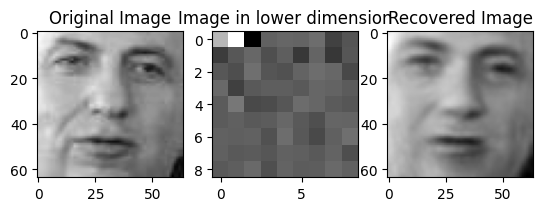

In [77]:
plt.subplot(131)
plt.title("Original Image")
plt.imshow(x_train_flatten[0].reshape(64, 64), cmap='gray')

plt.subplot(132)
plt.title("Image in lower dimension")
plt.imshow(x_train_new[0].reshape(9, 9), cmap='gray')

plt.subplot(133)
plt.title("Recovered Image")
plt.imshow(
    pca_object.inverse_transform(x_train_new[0].reshape(1, -1)).reshape(64, 64),cmap='gray')

plt.show()

Before training the model, use plot_eigenvalues insider PCA, that given eigenvalues, draws a CDF of them like here:<br/><br/>

![Picture1.jpg](https://encrypted-tbn1.gstatic.com/images?q=tbn:ANd9GcS3mOZk1x4X3ap9nuMnst5W5pMgOXF8r3Tmx1QcFX9mba_lleuB)

As seen in the tutorials, we use them to see how much "energy" we preserve from the data. Use this to choose optimal dimension to reduce into, such the preserves 95% of the energy.

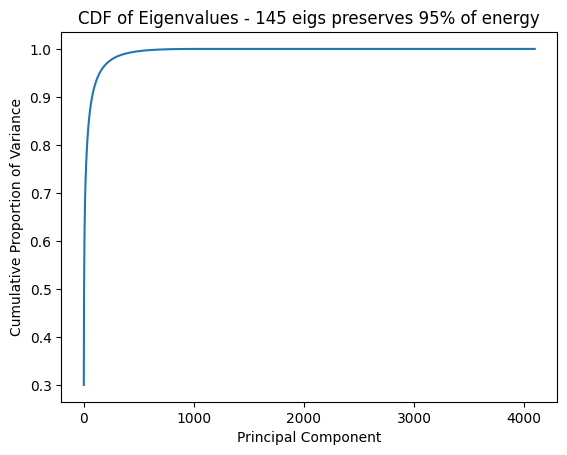

In [78]:
pca_object.plot_eigenvalues()

For the same image as before, show the result of applying PCA to it and recovering.<br/>
Is the result better? What is different from 81 dimensions? <br/>
<font color='red'>the recovered image that uses 145 components is better than the image that use 81 components, because the 145 component try to preserve about 95% of the variance therefore the image looks more sharper</font>

In [79]:
pca_object_145 = PCA(n_components=145)

x_train_145 = pca_object_145.fit_transform(x_train_flatten)
x_test_145 = pca_object_145.transform(x_test_flatten)

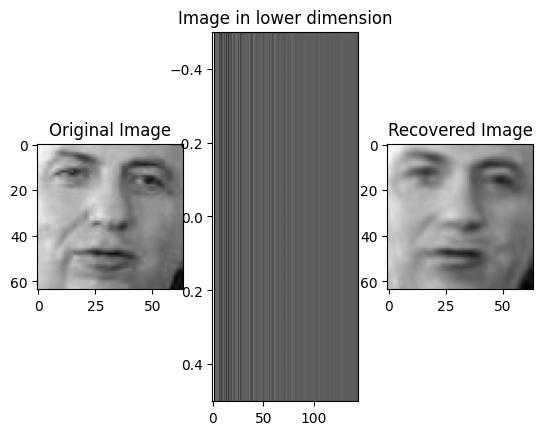

In [81]:
plt.subplot(131)
plt.title("Original Image")
plt.imshow(x_train_flatten[0].reshape(64, 64), cmap='gray')

plt.subplot(132)
plt.title("Image in lower dimension")
plt.imshow(x_train_145[0].reshape(1, -1), cmap='gray', aspect='auto')

plt.subplot(133)
plt.title("Recovered Image")
plt.imshow(pca_object_145.inverse_transform(x_train_145[0].reshape(1, -1)).reshape(64, 64),cmap='gray')

plt.show()

Now, you are ready to train the model. Use KNN, tune the best k using cross_val_score (with sklearn)

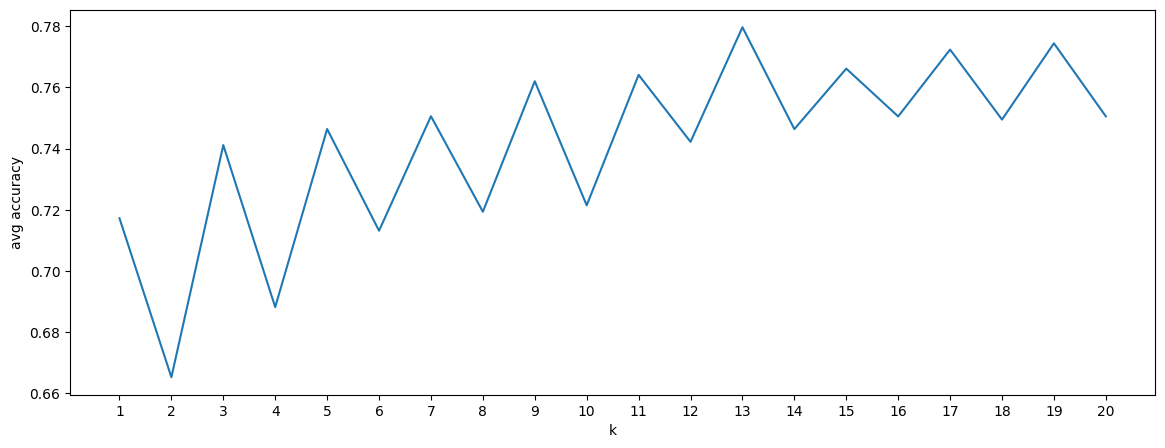

In [82]:
ks = list(range(1, 21))
accs = []

for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, x_train_new, y_train, cv=5)
    accs.append(scores.mean())

best_k = ks[np.argmax(accs)]

plt.figure(figsize=(14,5))
plt.plot(ks, accs)
plt.xlabel('k')
plt.xticks(ks)
plt.ylabel('avg accuracy')
plt.show()

Print the accuracy of your model on the test set.

In [83]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(x_train_new, y_train)

acc = knn.score(x_test_new, y_test)

print(f'Best k = {best_k}')
print(f'acc on test is {acc}')

Best k = 13
acc on test is 0.7842323651452282


Answer the following sum-up questions: <br/>
- What pre-proccessing actions were done on the images?
<font color='red'> first of all the image were converted to a grayscaler then we normalized the pixel values so we divided them by 255 therefore all the values become between 0 and 1 .
after this we flatted the image from 64x64 to one dimension vectors that contain 4096 features
and we split the data to train and test sets.</font>
- Should we apply Standard Scaler? Why?
<font color='red'> no, there is no need to use standard scaler , because we have already normalized all the pixel values and we have already center the data by subtracting the mean from the components
<font color='red'></font>


For the second part, we will use LDA **before** PCA

Use the model of LinearDiscriminantAnalysis from Sklearn, train the data and print the accuracy test using KNN. <br/>
Use the best k *you found earlier*.

Comparing LDA alone vs PCA alone (as dimensionality reduction), which one was better to this problem? Justify.

<font color='red'>the pca reached a higher test accuracy than pca ,in lda we got test accuracy 0.77.. ,and pca 0.784..., we got these results because the pca retain information that KNN can use more efficiently
</font>

In [84]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis()

x_train_lda = lda.fit_transform(x_train_flatten, y_train)
x_test_lda = lda.transform(x_test_flatten)

knn_lda = KNeighborsClassifier(n_neighbors=best_k)
knn_lda.fit(x_train_lda, y_train)

lda_acc = knn_lda.score(x_test_lda, y_test)

print(f'LDA test accuracy  {lda_acc}')

LDA test accuracy  0.7759336099585062


Now, repeat the same as above, but using the data <b>after</b> PCA and using the same k.

Was the combination of PCA and LDA helpful more than LDA alone? Why?

<font color='red'>yes the combination of pca and lda more helpful than lda alone .the pca+lda model achieved a test accuracy 0.8962,compared to 0.775 with lda alone, the pca reduces tthe dimension of the image than the lda finds the best projection to sperate between smiling and non smiling faces</font>

In [85]:
lda_after_pca = LinearDiscriminantAnalysis()

x_train_pca_lda = lda_after_pca.fit_transform(x_train_new, y_train)
x_test_pca_lda = lda_after_pca.transform(x_test_new)

knn_pca_lda = KNeighborsClassifier(n_neighbors=best_k)
knn_pca_lda.fit(x_train_pca_lda, y_train)

pca_lda_acc = knn_pca_lda.score(x_test_pca_lda, y_test)

print(f'PCA + LDA test accuracy: {pca_lda_acc}')

PCA + LDA test accuracy: 0.8962655601659751


## Question 3 - AdaBoost

In this exercise you will (pratially) implement AdaBoost and see how boosting can be applied to real-world problems, in detection of smiling or non-smiling face. <br/>



Until now, we saw AdaBoost only on 2d data and chose an axis aligned threshold, in parallel x or y axis, since we had 2 features.

In d dimensions we will still choose an axis aligned threshold (hyperplane) but along the feature axis (1,…,d) that gives the best weak learner.

In [86]:
#@title Find the best classifier. You can see this as blackbox
# Those who want to understand more - talk to me :)

def WL_by_sign_b(X_train, y_train, D, sign_b):
    F_min = sum(D[y_train == sign_b])       #the max error weight is all those who match sign_b
    tetha_min = X_train[0,0] - 1
    J_min = 0
    m, d = X_train.shape

    for j in range(d):    #choose index j for h, d = 5000
        values_wrt_j = np.column_stack((X_train[:,j],y_train, D))
        values_wrt_j = values_wrt_j[np.argsort(values_wrt_j[:, 0])]
        last = np.array([values_wrt_j[-1,0]+1, 0, 0])
        values_wrt_j = np.vstack((values_wrt_j, last))     # add x_m+1,j = x_m,y  +1
        F = sum(D[y_train == sign_b])

        #choose tetha for h
        Fs = F - np.cumsum(sign_b * values_wrt_j[:m,1] * values_wrt_j[:m,2])
        min_idx = np.argmin(Fs)
        if Fs[min_idx] < F_min:
          F_min = Fs[min_idx]
          tetha_min = 0.5 * sum(values_wrt_j[min_idx:min_idx+2,0])
          J_min = j

    return (J_min,tetha_min, F_min)

You are given the function ```get_hypothesis(X_train, y_train, D)``` which uses the train data, labels and the distribution over the samples (weights) and returns the best classifier.

Make sure to understand this tuple and the meaning of its variables.

In [87]:
def get_hypothesis(X_train, y_train, D):
    """
    return best weak learner h
    h = (h_pred, h_index, h_theta)
    - h_index is the feature in which the axis-aligned hyperplane is
    - h_theta is the treshold
    - h_pred is the label assigned if the feature h_index of the sample x <= h_theta
    """

    Min_feature_idx1, tetha_min1, F_min1 = WL_by_sign_b(X_train, y_train, D, 1)
    Min_feature_idx2, tetha_min2, F_min2 = WL_by_sign_b(X_train, y_train, D, -1)
    if F_min1 < F_min2:
        return (1, Min_feature_idx1, tetha_min1)
    else:
        return (-1, Min_feature_idx2, tetha_min2)

# returns +1 | -1 only. For 0 returns +1. Use this
def sign(expr):
  return np.sign(np.sign(expr) + 0.5)

Implement the following:<br/>
- ```predict_wrt_h(X, h)```: should return the predictions of $X\in\mathbb{R}^{n\times d}$, according to the classifier.
- ```zo_loss_wrt_h(X, y, h)```: returns the 0-1 loss (delta) for $X\in\mathbb{R}^{n\times d}$, if predictions differ from the real labels.
- ```get_weighted_error(X_train, y_train, D, h)```: returns the $ε_t$, the weights sum of the misclassified samples.


In [88]:
def predict_wrt_h(X, h):
    """
    h = (h_pred, h_index, h_theta)
    - h_index is the feature in which the axis-aligned hyperplane is
    - h_theta is the treshold
    - h_pred is the label assigned if the feature h_index of the sample x <= h_theta

    This function should return h_pred if the h_index feature of X is less (or equal) than the treshold h_theta
    otherwise, returns the opposite of h_pred
    """

    h_pred, h_index, h_theta = h
    return np.where(X[:, h_index] <= h_theta, h_pred, -h_pred)

def zo_loss_wrt_h(X, y, h):
    """
    return delta(h(x),y), which is array of 0-1
    """
    predictions = predict_wrt_h(X, h)
    return (predictions != y).astype(int)

def get_weighted_error(X_train, y_train, D, h):
    """
    return epsilon_t
    e.g sum of D[i]*delta(h(xi),yi)
    """
    losses = zo_loss_wrt_h(X_train, y_train, h)
    return np.sum(D * losses)

Implement ```run_adaboost(X_train, y_train, T)```: runs the AdaBoost algorithm for T steps and returns a list of classifiers (hypotheses), and list of alpha values ($α_t$ for each iteration T). <br/>
Hint: the only 'for' loop needed is over T. The rest can be done efficiently using numpy and previous implemented functions.

In [89]:
def run_adaboost(X_train, y_train, T):
    """
    Returns:
        hypotheses :
            A list of T tuples describing the hypotheses chosen by the algorithm.
            Each tuple has 3 elements (h_pred, h_index, h_theta)
            h = (h_pred, h_index, h_theta)
            - h_index is the feature in which the axis-aligned hyperplane is
            - h_theta is the treshold
            - h_pred is the label assigned if the feature h_index of the sample x <= h_theta
        alpha_vals :
            A list of T float values, which are the alpha values obtained in every
            iteration of the algorithm.
    """
    alpha_vals = []
    hypotheses = []
    D = np.ones(len(X_train)) / len(X_train)

    for _ in range(T):
        h = get_hypothesis(X_train, y_train, D)
        hypotheses.append(h)

        epsilon_t = get_weighted_error(X_train, y_train, D, h)



        alpha_t = 0.5 * np.log((1 - epsilon_t) / epsilon_t)
        alpha_vals.append(alpha_t)

        predictions = predict_wrt_h(X_train, h)

        D = D * np.exp(-alpha_t * y_train * predictions)
        D = D / np.sum(D)
    return hypotheses, alpha_vals

Implement ```calc_error(data, labels, hypotheses, alpha_vals)```:

For each iteration $t=1,...,T$, calculate the error rate (from $1,...,t$). <br/>

In [90]:
def calc_error(data, labels, hypotheses, alpha_vals):
    """
    calc empirical error
    classfication is sign of sum of a_t*h_t(x)

    Return list of mean errors using 1,...,T hypotheses
    """
    error_all_t = []
    scores = np.zeros(len(data))

    for t in range(len(hypotheses)):


        scores += alpha_vals[t] * predict_wrt_h(data, hypotheses[t])

        predictions = sign(scores)
        error = np.mean(predictions != labels)

        error_all_t.append(error)

    return error_all_t

Prepear the adaboost run.
- 80 iterations.
- Use the labels 0/1 into -1/1.

This is due to the fact that classification based on sign which is -1,+1.

In [91]:
T = 80

y_train_ada = y_train.copy()
y_test_ada = y_test.copy()

y_train_ada[y_train == 0] = -1
y_test_ada[y_test == 0] = -1

Run the AdaBoost algorithm on the train and test <b>after</b> performing PCA.

In [92]:
hypotheses, alpha_vals = run_adaboost(x_train_new, y_train_ada, T)

Plot the train and test erros as function of T

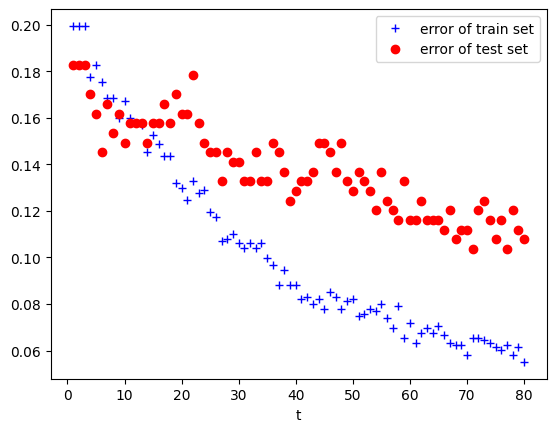

In [93]:
train_error_t = calc_error(x_train_new, y_train_ada, hypotheses, alpha_vals)
test_error_t = calc_error(x_test_new, y_test_ada, hypotheses, alpha_vals)
X = np.arange(1,T+1)
plt.plot(X, train_error_t ,'b+', label = 'error of train set')
plt.plot(X, test_error_t ,'ro', label = 'error of test set')
plt.xlabel('t')
plt.legend()
plt.show()

Get the train and test accuracy

In [94]:
print(f'final train accuracy {1-train_error_t[-1]}')
print(f'final test accuracy {1-test_error_t[-1]}')

final train accuracy 0.9449064449064449
final test accuracy 0.892116182572614


Run the AdaBoost algorithm on the train and test <b>before</b> performing PCA. <br/>

Note: an efficient implementation should take up to 4 minutes of running.

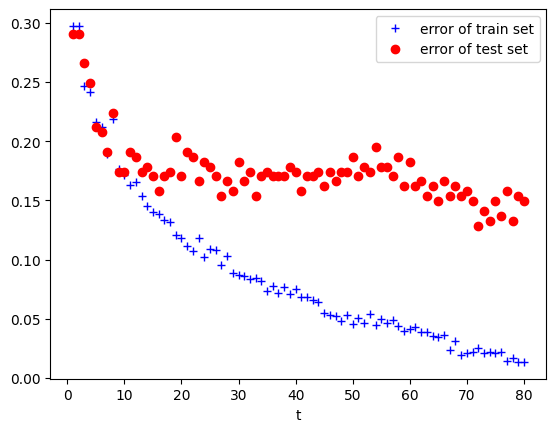

In [95]:
hypotheses, alpha_vals = run_adaboost(x_train_flatten, y_train_ada, T)
train_error_t = calc_error(x_train_flatten, y_train_ada, hypotheses, alpha_vals)
test_error_t = calc_error(x_test_flatten, y_test_ada, hypotheses, alpha_vals)
X = np.arange(1,T+1)
plt.plot(X, train_error_t ,'b+', label = 'error of train set')
plt.plot(X, test_error_t ,'ro', label = 'error of test set')
plt.xlabel('t')
plt.legend()
plt.show()

In [96]:
print(f'final train accuracy {1-train_error_t[-1]}')
print(f'final test accuracy {1-test_error_t[-1]}')

final train accuracy 0.9864864864864865
final test accuracy 0.8506224066390041


Answer the following questions:
- Which dataset would you prefer to run on AdaBoost - before or after PCA?
<font color='red'>
i would choose run adaboost after PCA,although we got a lower test accuracy when we run the algorithm after using pca ,before pca we got higher train accuracy and large gap between test and training accuracy ,which means there is a possible overfit</font>

- What are your conclusions on using AdaBoost in general?

<font color='red'>adaboost gives a strong classifier from combiniation of weak classifires,after every iteration the algorithm foucsed on missclassified samples therfore the training error will decrease, however the test error decrease after few iterations,therefore many iterations may increase the gap between the training and the test , which leads to overfitting  </font>

## Bonus: 10 pts
Repeat the process of AdaBoost (after PCA) but this time apply two strong classifiers:
1. SVM lines (a line in j features)
2. Intervals (a,b in one among the j features, like parallel thresholds).

Of course, you are not required (and actually forbidden) to invent a weighted dataset learner (but its nice to have), so you should apply the althernative technique discussed in class.

Use T=80, provide traing and test curves (just like the original task) and explain what happened with each hypothesis family.

In [97]:
from sklearn.svm import SVC


class IntervalClassifier:

    def __init__(self):
        self.feature_index = None
        self.a = None
        self.b = None
        self.inside_label = None

    def find_best_subarray(self, values, find_max=True):
        best_sum = values[0]
        current_sum = values[0]
        best_start = 0
        best_end = 0
        current_start = 0

        for i in range(1, len(values)):
            if find_max:
                if current_sum + values[i] < values[i]:
                    current_sum = values[i]
                    current_start = i
                else:
                    current_sum += values[i]

                if current_sum > best_sum:
                    best_sum = current_sum
                    best_start = current_start
                    best_end = i

            else:
                if current_sum + values[i] > values[i]:
                    current_sum = values[i]
                    current_start = i
                else:
                    current_sum += values[i]

                if current_sum < best_sum:
                    best_sum = current_sum
                    best_start = current_start
                    best_end = i

        return best_start, best_end, best_sum

    def fit(self, X, y):
        best_error = np.inf

        for j in range(X.shape[1]):
            order = np.argsort(X[:, j])
            x_sorted = X[order, j]
            y_sorted = y[order]

            signed_labels = np.where(y_sorted == 1, 1, -1)

            left_pos, right_pos, best_positive_sum = self.find_best_subarray(signed_labels, find_max=True)
            positive_error = np.sum(y_sorted == 1) - best_positive_sum

            if positive_error < best_error:
                best_error = positive_error
                self.feature_index = j
                self.inside_label = 1

                if left_pos == 0:
                    self.a = -np.inf
                else:
                    self.a = (x_sorted[left_pos - 1] + x_sorted[left_pos]) / 2

                if right_pos == len(x_sorted) - 1:
                    self.b = np.inf
                else:
                    self.b = (x_sorted[right_pos] + x_sorted[right_pos + 1]) / 2

            left_neg, right_neg, best_negative_sum = self.find_best_subarray(signed_labels, find_max=False)
            negative_error = np.sum(y_sorted == -1) + best_negative_sum

            if negative_error < best_error:
                best_error = negative_error
                self.feature_index = j
                self.inside_label = -1

                if left_neg == 0:
                    self.a = -np.inf
                else:
                    self.a = (x_sorted[left_neg - 1] + x_sorted[left_neg]) / 2

                if right_neg == len(x_sorted) - 1:
                    self.b = np.inf
                else:
                    self.b = (x_sorted[right_neg] + x_sorted[right_neg + 1]) / 2

        return self

    def predict(self, X):
        inside_interval = (X[:, self.feature_index] > self.a) & (X[:, self.feature_index] <= self.b)
        return np.where(inside_interval, self.inside_label, -self.inside_label)

In [98]:
def run_adaboost_strong_classifier(X_train, y_train, T, classifier_type):
    hypotheses = []
    alpha_vals = []
    D = np.ones(len(X_train)) / len(X_train)
    random_generator = np.random.RandomState(42)

    for t in range(T):
        sampled_indices = random_generator.choice(len(X_train), size=len(X_train), replace=True, p=D)
        X_sample = X_train[sampled_indices]
        y_sample = y_train[sampled_indices]

        if classifier_type == 'svm':
            classifier = SVC(kernel='linear')
        elif classifier_type == 'interval':
            classifier = IntervalClassifier()
        else:
            raise ValueError("classifier_type must be 'svm' or 'interval'")

        classifier.fit(X_sample, y_sample)
        predictions = classifier.predict(X_train)

        epsilon_t = np.sum(D * (predictions != y_train))

        if epsilon_t == 0:
            hypotheses.append(classifier)
            alpha_vals.append(1)
            break

        if epsilon_t >= 0.5:
            break

        alpha_t = 0.5 * np.log((1 - epsilon_t) / epsilon_t)

        hypotheses.append(classifier)
        alpha_vals.append(alpha_t)

        D = D * np.exp(-alpha_t * y_train * predictions)
        D = D / np.sum(D)

    return hypotheses, alpha_vals

In [99]:
def calc_strong_classifier_error(data, labels, hypotheses, alpha_vals):
    errors = []
    scores = np.zeros(len(data))

    for t in range(len(hypotheses)):
        scores += alpha_vals[t] * hypotheses[t].predict(data)
        predictions = sign(scores)
        errors.append(np.mean(predictions != labels))

    return errors

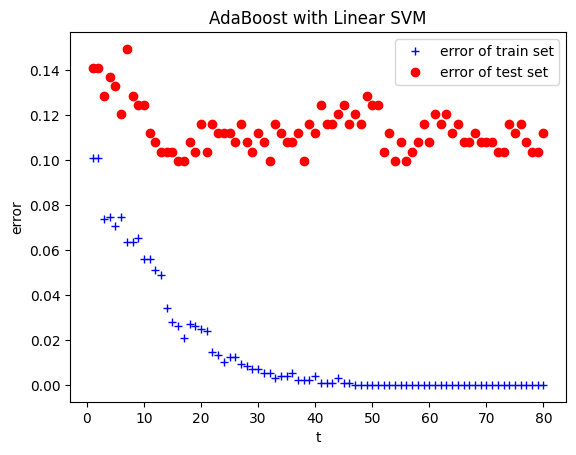

final SVM train accuracy 1.0
final SVM test accuracy 0.8879668049792531


In [100]:
T = 80

svm_hypotheses, svm_alpha_vals = run_adaboost_strong_classifier(x_train_new, y_train_ada, T, 'svm')

svm_train_error = calc_strong_classifier_error(x_train_new, y_train_ada, svm_hypotheses, svm_alpha_vals)
svm_test_error = calc_strong_classifier_error(x_test_new, y_test_ada, svm_hypotheses, svm_alpha_vals)

iterations = np.arange(1, len(svm_train_error) + 1)

plt.plot(iterations, svm_train_error, 'b+', label='error of train set')
plt.plot(iterations, svm_test_error, 'ro', label='error of test set')
plt.xlabel('t')
plt.ylabel('error')
plt.title('AdaBoost with Linear SVM')
plt.legend()
plt.show()

print(f'final SVM train accuracy {1 - svm_train_error[-1]}')
print(f'final SVM test accuracy {1 - svm_test_error[-1]}')

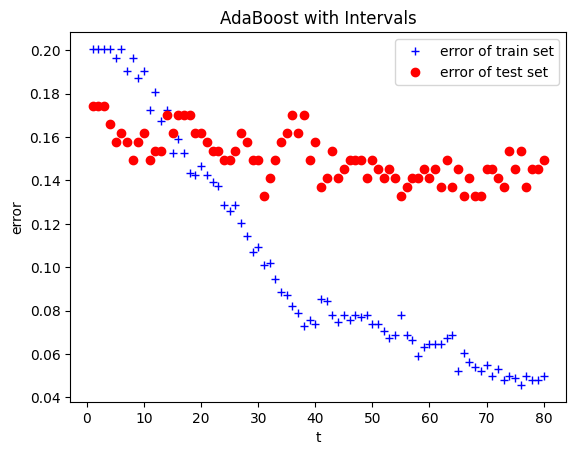

final interval train accuracy 0.9501039501039501
final interval test accuracy 0.8506224066390041


In [101]:
interval_hypotheses, interval_alpha_vals = run_adaboost_strong_classifier(x_train_new, y_train_ada, T, 'interval')

interval_train_error = calc_strong_classifier_error(x_train_new, y_train_ada, interval_hypotheses, interval_alpha_vals)
interval_test_error = calc_strong_classifier_error(x_test_new, y_test_ada, interval_hypotheses, interval_alpha_vals)

iterations = np.arange(1, len(interval_train_error) + 1)

plt.plot(iterations, interval_train_error, 'b+', label='error of train set')
plt.plot(iterations, interval_test_error, 'ro', label='error of test set')
plt.xlabel('t')
plt.ylabel('error')
plt.title('AdaBoost with Intervals')
plt.legend()
plt.show()

print(f'final interval train accuracy {1 - interval_train_error[-1]}')
print(f'final interval test accuracy {1 - interval_test_error[-1]}')

<font color='red'>

the linear svm hypothesis have better results  than the interval hypothesis.however adaboost with linear svm reached 100% training accuracy and about 88% test accuracy, while adaboost with intervals reached about 96.3% training accuracy and 83.8% test accuracy. the svm classifiers can separate the pca features more effectively, but the gap between training and test accuracy indicates some overfitting </font>

## Question 4 - Deep Learning

In this excersise you will implement the foundations of deep learning on the smiling faces problem.<br/>
It is highly recommended to use Colab to run using GPU.

Import libraries

In [102]:
import matplotlib.pyplot as plt
import torch

device = 'cuda' if torch.cuda.is_available() else 'cpu'

Just to make sure your labels are 0/1
Softmax must use predictions of 0,1,..,C-1

In [103]:

y_train[y_train == -1] = 0
y_test[y_test == -1] = 0

# when using torch, just like numpy, we need to cast everything into 'tensor'

y_train = torch.tensor(y_train, dtype=torch.long).to(device)
y_test = torch.tensor(y_test, dtype=torch.long).to(device)

x_train_flatten = torch.tensor(x_train_flatten, dtype=torch.float32).to(device)
x_test_flatten = torch.tensor(x_test_flatten, dtype=torch.float32).to(device)

We want (and must) apply StandardScaler on our data. However, usually in deep learning it's a hard problem. Do you wish, on any train process to start calculating mean and std of 1M images?

Hence, for famous datasets (such as MNIST, CIFAR) you will be able to find the mean and std in web search. In our problem, Sharon (not a lazy TA), has already calculated mean and std of the train (think of it as the 'fit' is already given to you).

In [104]:
class SharonScaler:
    def __init__(self):
        self.mean = 0.5082
        self.std = 0.175

    def transform(self, X):
        return (X - self.mean) / self.std

    def inverse_transform(self, X):
        return X * self.std + self.mean

scaler = SharonScaler()

x_train = scaler.transform(x_train_flatten)
x_test = scaler.transform(x_test_flatten)

Run this short guide about autograd and make sure to understand it.

In [105]:
a = torch.tensor([3.0], requires_grad=True)
b = a ** 2
b.backward()
print(a.grad)

tensor([6.])


You are given a partial implementation of Linear layer.

Its methods are:
- `__init__(self, input_size, output_size)`: Given number of inputs and outputs, initalize $W\in\mathbb{R}^{\text{in}\times\text{out}}\sim \mathcal{N}(0,\frac{2}{\text{in}})$, bias $b\in\mathbb{R}^{\text{out}}$ of zeros.<!--Actually, make W~N(0,1)-->
- `forward(self, x)`: Given $x\in\mathbb{R}^{n\times\text{in}}$, apply a linear layer on it by $W^\top x + b$.
    - the returned value is the output of the linear layer.
- `update(self, learning_rate)`: updates the weights and biases using self.`self.grad_weights` and `self.grad_bias` and  GD.
- `backward(self, loss)`: Calculate $\dfrac{\partial \mathcal{L}}{\partial w},\dfrac{\partial \mathcal{L}}{\partial b}$

Complete the missing implementation

In [106]:
class Linear:
    def __init__(self, input_size, output_size):
        self.weights = torch.randn(output_size, input_size) * torch.sqrt(torch.tensor(2.0 / input_size))
        self.weights.requires_grad_(True)

        self.bias = torch.zeros(output_size)
        self.bias.requires_grad_(True)

    def forward(self, x):
        return x @ self.weights.T + self.bias


    def update(self, learning_rate):
        with torch.no_grad():
            self.weights -= learning_rate * self.weights.grad
            self.bias -= learning_rate * self.bias.grad

    def zero_grad(self):
        if self.weights.grad is not None:
            self.weights.grad.zero_()

        if self.bias.grad is not None:
            self.bias.grad.zero_()

    def to(self, device):
        self.weights = self.weights.detach().to(device).requires_grad_(True)
        self.bias = self.bias.detach().to(device).requires_grad_(True)

    def params(self):
        return torch.prod(torch.tensor(self.weights.shape)) + torch.prod(torch.tensor(self.bias.shape))

1. Prove that $\text{ReLu}'(x)=\mathbb{I}\{x>0\}$
2. Calculate $\sigma'(x)$.

<font color='red'>Write here your answers and explain them.</font>

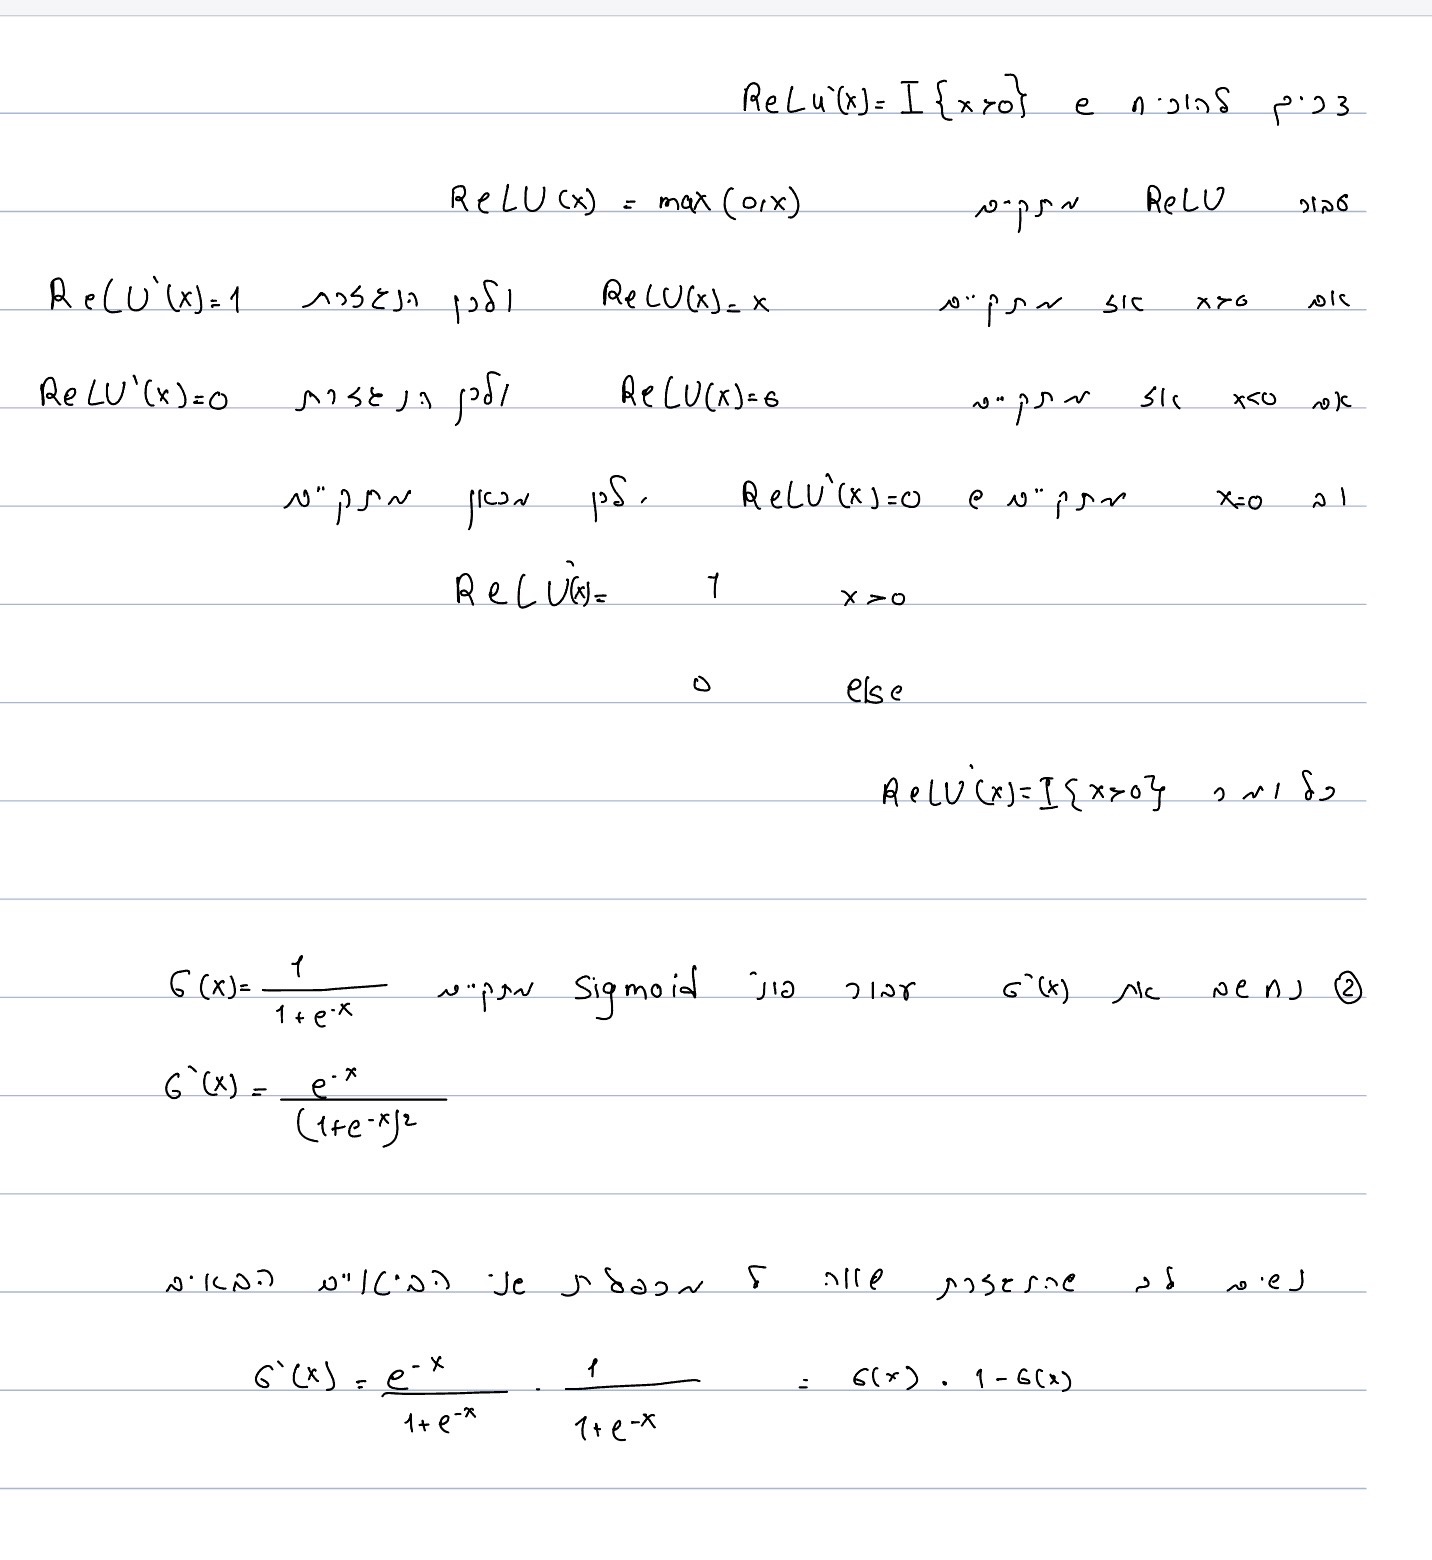

In [107]:
class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

class Sigmoid:
    def forward(self, x):
        self.output = 1 / (1 + np.exp(-x))
        return self.output

You are given a partial implementation of Simple neural network.

Its methods are:
- `__init__(self, input_size, output_size, hidden_size=32)`: Given number of inputs and outputs, initialize one single linear layer (for now, ignore hidden_size).
- `forward(self, x)`: Given x, apply the layers on it (for start, the one single layer) and return the logits. do not apply any softmax.
- `loss(self, y_true)`: Return the corss entropy loss by the formula learned in class:
$$
\mathcal{L}=-\frac{1}{n}\sum_i\sum_{k\in\mathcal{C}}\log(\hat{y}_k)\cdot\mathbb{I}_{y_i=k}
$$
Of course, averaged over the batch_size.


In [108]:
class SimpleNN:
    def __init__(self, input_size, output_size, hidden_size=32):

        self.layers = [
            Linear(input_size, output_size)
        ]

    def forward(self, x):

        for layer in self.layers:
            x = layer.forward(x)

        self.logits = x
        return self.logits

    def loss(self, y_true):

        log_probs = log_softmax(self.logits)
        batch_size = y_true.size(0)

        loss = -log_probs[torch.arange(batch_size), y_true].mean()

        return loss

    def to(self, device):
        for layer in self.layers:
            if hasattr(layer, "to"):
                layer.to(device)

    def params(self):

        return sum(layer.params() for layer in self.layers)

Implement `log_softmax(self, logits)`: given $\text{logits}\in\mathbb{R}^{n\times\text{out}}$, representing the output, apply log-softmax as learned in class by using:
$$
\text{softmax}=\frac{e^{y_i-C}}{\sum_j e^{y_j-C}}
$$
where $C=\max_i\{e^{y_i}\}$, for numerical stability. Output dimensions should remain as is, as we only normalize the layer's outputs.<br/>
Note: <b>DO NOT</b> calculate the log of this expression, but use logarrithmic rules to calculate is.

In [109]:
def log_softmax(logits):

    c = torch.max(logits, dim=1, keepdim=True).values
    logits = logits - c
    log_sum_exp = torch.log(torch.sum(torch.exp(logits), dim=1, keepdim=True))

    return logits - log_sum_exp


def compute_accuracy(logits, label):

    log_probs = log_softmax(logits)
    pred = torch.argmax(logits, axis=1)
    accuracy = torch.count_nonzero(pred == label) / len(label)

    return accuracy

Here we define the Optimizer class. <br/>
Here, we keep it simple but in reality - this is the place to use other optimization methods, or apply decaying learning rate.<br/>

Implement `step(self, learning_rate)`: goes through each layers and updates the parameters.

In [110]:
class Optimizer:
    def __init__(self, model):
        self.model = model

    def step(self, learning_rate):

        for layer in self.model.layers:
            if hasattr(layer, "update"):
                layer.update(learning_rate)

    def zero_grad(self):
        for layer in self.model.layers:
            if isinstance(layer, Linear):
                layer.zero_grad()

You are ready to start training! Let's try to use one linear layer, with 300 epochs, full size batch and 0.01 learning rate.

In [111]:
from tqdm import tqdm

number_epochs    = 300
learning_rate = 1e-2

train_loss = torch.zeros(number_epochs)
train_accuracy = torch.zeros(number_epochs)

test_loss = torch.zeros(number_epochs)
test_accuracy = torch.zeros(number_epochs)

model = SimpleNN(x_train_flatten.shape[1], output_size=2)
model.to(device)
print(f"There are {model.params()} learnable parameters")

optimzer = Optimizer(model)

# iteration for epoch
for i in tqdm(range(number_epochs)):

    optimzer.zero_grad()

    logits = model.forward(x_train_flatten)
    loss = model.loss(y_train)

    loss.backward()                     # compute gradients of the entire computation graph
    optimzer.step(learning_rate)        # apply the update rule upon all the parameters in the net

    # train
    train_loss[i]       = loss.item()
    train_accuracy[i]   = compute_accuracy(logits, y_train)

    # test
    logits              = model.forward(x_test_flatten)
    test_loss[i]        = model.loss(y_test).item()
    test_accuracy[i] = compute_accuracy(logits, y_test)

There are 8194 learnable parameters


100%|██████████| 300/300 [00:03<00:00, 86.62it/s]


Plot loss and accuracy.
1. Explain what happened in the graphs and why is that.
<font color='red'> as we can see from the graphs the test an train error keep decreasing while the train and the test accuracy increasing , we can conclude from these results that the network learning better.</font>

2. Read on google and explain in one sentence, why we need `optimzer.zero_grad`().
<font color='red'> we need optimizer.zero_grad() because gradients accumulate by default on every backward pass so the optimizer.zero_grad() clears the gradients from the previous iteration so that each update is based only on the current batch </font>

3. Why do we need `.to(device)`? What do you think happens if we remove it?

<font color='red'>Write here your answers and explain them</font>

<font color='red'> we need to use .to(device) to move data and models between the CPU and the GPU if we removing it , the model and the data may be on a different devices therefore we can get a runtime error

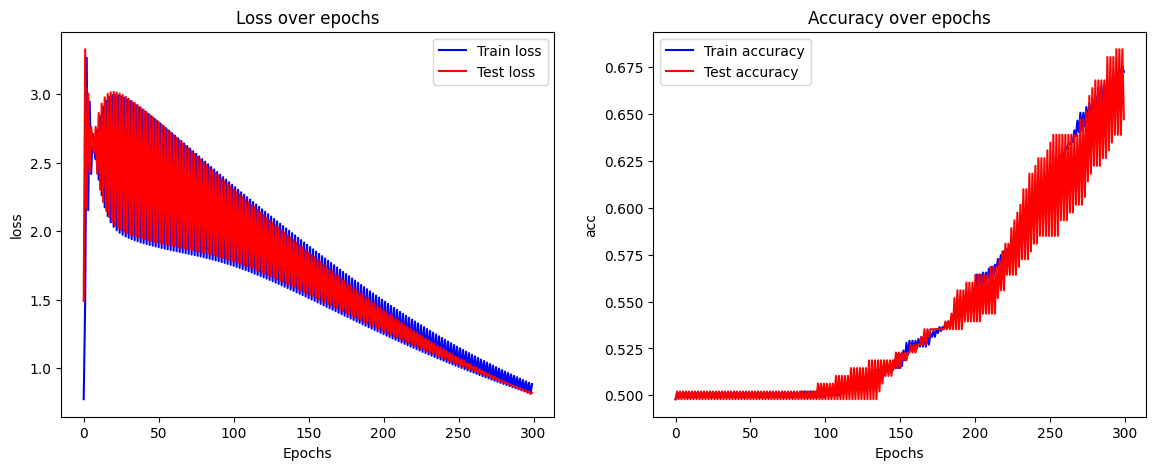

In [112]:
# loss
epochs = range(number_epochs)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_loss, label='Train loss', color='blue')
plt.plot(epochs, test_loss, label='Test loss', color='red')

plt.xlabel('Epochs')
plt.ylabel('loss')
plt.title('Loss over epochs')

plt.legend()

# accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracy, label='Train accuracy', color='blue')
plt.plot(epochs, test_accuracy, label='Test accuracy', color='red')

plt.xlabel('Epochs')
plt.ylabel('acc')
plt.title('Accuracy over epochs')

plt.legend()

plt.show()

Now its the time for the task! You need to reach ~90% accuracy on test.<br/>
Guidlines:
- Use more epochs.
- Use more layers.
- Use hidden_size.
- Use activation functions.
- If the graph is super noisy - it means that LR is too large.
- If you see underfit.. you know what to do.
- If you see overfit.. you probably won't.

<font color='red'>
to improve the model, i added hidden layers  which can help the model to improve the learning (learn more facial features), and ReLU activation functions that make the model non linear ,increased the number of training epochs from 300 to 1500, i reduced the learning rate from 1e-2 to 1e-3 because large learning rate could make the model learn the noise, these modifications increased the power of the network and enabled it to learn more complex image patterns,therefore the test accuracy improved from 70% in the original linear model to about 90%.

</font>

In [113]:
class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

In [114]:
class SimpleNN:
    def __init__(self, input_size, output_size, hidden_size=128):
        self.layers = [Linear(input_size, 256),ReLU(),Linear(256, 128),ReLU(),Linear(128, 64),ReLU(),Linear(64, output_size)]

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)

        self.logits = x
        return self.logits

    def log_softmax(self, logits):
        c = torch.max(logits, dim=1, keepdim=True).values
        shifted_logits = logits - c
        log_sum_exp = torch.log(torch.sum(torch.exp(shifted_logits), dim=1, keepdim=True))

        return shifted_logits - log_sum_exp

    def loss(self, y_true):
        log_probs = self.log_softmax(self.logits)
        batch_size = y_true.size(0)

        loss = -log_probs[torch.arange(batch_size, device=y_true.device), y_true].mean()

        return loss

    def to(self, device):
        for layer in self.layers:
            if hasattr(layer, "to"):
                layer.to(device)

    def params(self):
        return sum(layer.params() for layer in self.layers if hasattr(layer, "params"))

In [115]:
class Optimizer:
    def __init__(self, model):
        self.model = model

    def step(self, learning_rate):
        for layer in self.model.layers:
            if hasattr(layer, "update"):
                layer.update(learning_rate)

    def zero_grad(self):
        for layer in self.model.layers:
            if hasattr(layer, "zero_grad"):
                layer.zero_grad()

In [116]:
from tqdm import tqdm

number_epochs = 1500
learning_rate = 1e-3

train_loss = torch.zeros(number_epochs)
train_accuracy = torch.zeros(number_epochs)

test_loss = torch.zeros(number_epochs)
test_accuracy = torch.zeros(number_epochs)

model = SimpleNN(
    x_train_flatten.shape[1],
    output_size=2,
    hidden_size=128
)

model.to(device)

print(f"There are {model.params()} learnable parameters")

optimizer = Optimizer(model)

for i in tqdm(range(number_epochs)):

    optimizer.zero_grad()

    logits = model.forward(x_train_flatten)

    loss = model.loss(y_train)

    loss.backward()

    optimizer.step(learning_rate)

    train_loss[i] = loss.item()

    train_accuracy[i] = compute_accuracy(
        logits,
        y_train
    )

    with torch.no_grad():

        test_logits = model.forward(
            x_test_flatten
        )

        test_loss[i] = model.loss(
            y_test
        ).item()

        test_accuracy[i] = compute_accuracy(
            test_logits,
            y_test
        )

There are 1090114 learnable parameters


100%|██████████| 1500/1500 [02:23<00:00, 10.46it/s]


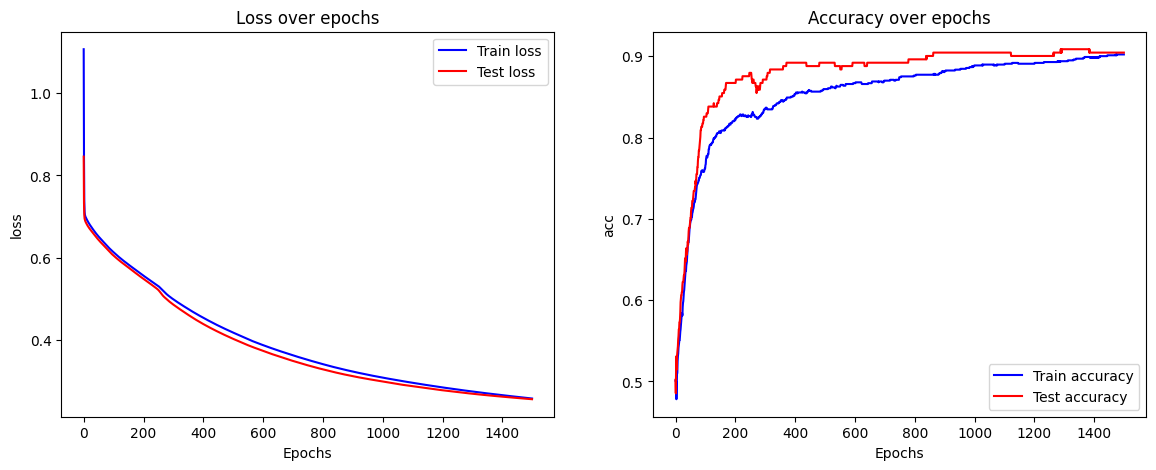

In [117]:
# loss
epochs = range(number_epochs)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_loss, label='Train loss', color='blue')
plt.plot(epochs, test_loss, label='Test loss', color='red')

plt.xlabel('Epochs')
plt.ylabel('loss')
plt.title('Loss over epochs')

plt.legend()

# accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracy, label='Train accuracy', color='blue')
plt.plot(epochs, test_accuracy, label='Test accuracy', color='red')

plt.xlabel('Epochs')
plt.ylabel('acc')
plt.title('Accuracy over epochs')

plt.legend()

plt.show()